# HR Analytics - Employee Attrition
## Notebook 2: Machine Learning - Attrition Prediction

**Goal:** predict which employees are likely to leave, rank the drivers, and export predictions for Power BI.

**Workflow**
1. Prepare features (encoding & scaling)
2. Train Logistic Regression, Decision Tree and Random Forest
3. Evaluate: accuracy, precision, recall, F1, confusion matrix, ROC-AUC
4. Feature importance
5. Predict and export to CSV for the Power BI dashboard

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

import eda, model_training as mt
eda.set_style()
IMG = "../images/model"
df = pd.read_csv("../data/processed/cleaned_hr_data.csv")
print(df.shape)

(1470, 42)


## 1. Feature preparation
- **Target:** `Attrition_Flag` (1 = left, 0 = stayed)
- **Removed:** `EmployeeID`, the target itself, and engineered label/band columns (they duplicate raw features)
- **Encoding:** one-hot encoding for categorical features
- **Scaling:** `StandardScaler` for Logistic Regression (distance-based); tree models are scale-invariant so they are left unscaled

In [2]:
X, y, num_cols, cat_cols = mt.prepare_xy(df)
print(f"{X.shape[1]} features -> {len(num_cols)} numeric, {len(cat_cols)} categorical")
print("Categorical:", cat_cols)
print()
print("Class balance:")
y.value_counts(normalize=True).rename({0: "Stayed", 1: "Left"}).round(3)

27 features -> 20 numeric, 7 categorical
Categorical: ['Gender', 'MaritalStatus', 'EducationField', 'Department', 'JobRole', 'BusinessTravel', 'OverTime']

Class balance:


Attrition_Flag
Stayed    0.846
Left      0.154
Name: proportion, dtype: float64

The classes are **imbalanced (~15 % leavers)**, so:
- the split is **stratified**
- models use **`class_weight='balanced'`**
- accuracy alone is misleading (predicting "everyone stays" gives ~85 %), so **recall and F1 on the "Left" class** are the main metrics

In [3]:
X_train, X_test, y_train, y_test = mt.split_data(X, y)
print(f"Train: {len(X_train)} rows ({y_train.mean():.1%} left)  |  Test: {len(X_test)} rows ({y_test.mean():.1%} left)")

Train: 1176 rows (15.5% left)  |  Test: 294 rows (15.3% left)


## 2. Train & tune the models
5-fold cross-validated grid search on the **training set only**, optimising F1.

In [4]:
models = mt.build_models(num_cols, cat_cols)
fitted, cv_scores, best_params = mt.tune_models(models, X_train, y_train)
for name, p in best_params.items():
    print(f"{name:20s} CV F1 = {cv_scores[name]:.3f}   best params: {p}")

Logistic Regression  CV F1 = 0.434   best params: {'clf__C': 3}
Decision Tree        CV F1 = 0.371   best params: {'clf__max_depth': 4, 'clf__min_samples_leaf': 40}
Random Forest        CV F1 = 0.444   best params: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 8, 'clf__n_estimators': 300}


## 3. Evaluation on the unseen test set

In [5]:
metrics = mt.evaluate(fitted, X_test, y_test)
metrics

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.660,0.273,0.733,0.398,0.750
Decision Tree,0.690,0.283,0.667,0.397,0.732
Random Forest,0.796,0.385,0.556,0.455,0.810


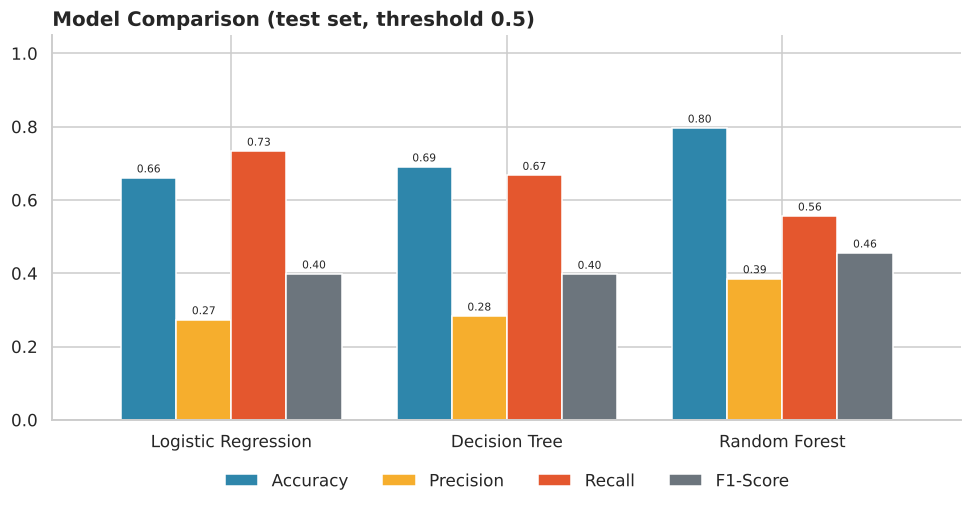

In [6]:
mt.plot_model_comparison(metrics, IMG);

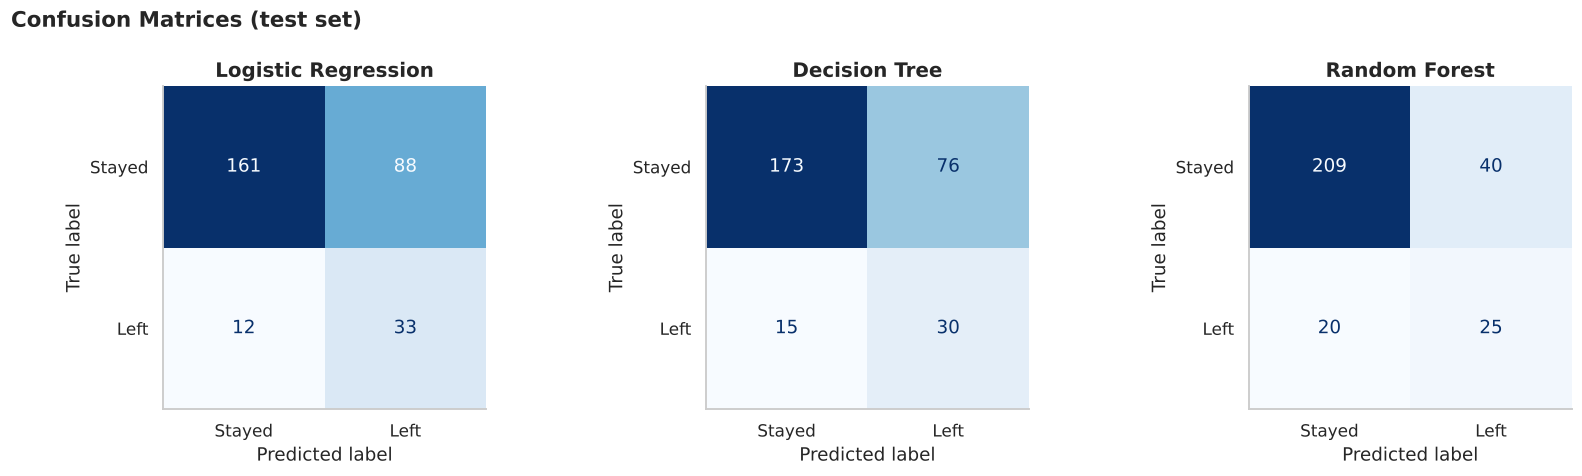

In [7]:
mt.plot_confusion_matrices(fitted, X_test, y_test, IMG);

In [8]:
for name, m in fitted.items():
    pred = (m.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    print(f"--- {name} ---")
    print(classification_report(y_test, pred, target_names=["Stayed", "Left"], digits=3))

--- Logistic Regression ---
              precision    recall  f1-score   support

      Stayed      0.931     0.647     0.763       249
        Left      0.273     0.733     0.398        45

    accuracy                          0.660       294
   macro avg      0.602     0.690     0.580       294
weighted avg      0.830     0.660     0.707       294

--- Decision Tree ---
              precision    recall  f1-score   support

      Stayed      0.920     0.695     0.792       249
        Left      0.283     0.667     0.397        45

    accuracy                          0.690       294
   macro avg      0.602     0.681     0.595       294
weighted avg      0.823     0.690     0.731       294

--- Random Forest ---
              precision    recall  f1-score   support

      Stayed      0.913     0.839     0.874       249
        Left      0.385     0.556     0.455        45

    accuracy                          0.796       294
   macro avg      0.649     0.697     0.665       294
we

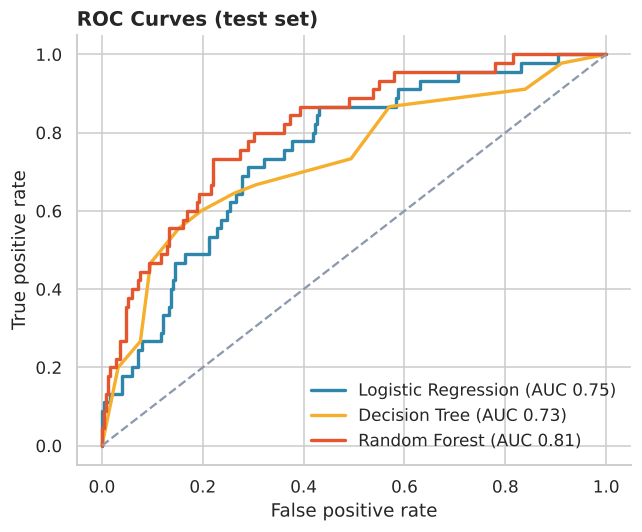

In [9]:
mt.plot_roc(fitted, X_test, y_test, IMG);

**Reading the results**
- **Random Forest** gives the best balance of precision, recall and ROC-AUC, so it is selected (selection is based on cross-validation F1 on the training data, not on the test set).
- The Decision Tree is the most interpretable but the weakest; Logistic Regression is a solid, explainable baseline.
- Precision for the "Left" class is moderate: for every 10 employees flagged, roughly 4 genuinely leave. That is acceptable for an *early-warning list* where the cost of a retention conversation is low, but the list should not be used for punitive decisions.

## 4. Decision threshold

In [10]:
best_name = max(cv_scores, key=cv_scores.get)
best = fitted[best_name]
thr = mt.best_threshold(best, X_train, y_train)
print(f"Selected model: {best_name}")
print(f"F1-optimal threshold (from out-of-fold TRAIN predictions): {thr:.2f}")
mt.evaluate({best_name: best}, X_test, y_test, threshold=thr)

Selected model: Random Forest
F1-optimal threshold (from out-of-fold TRAIN predictions): 0.50


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Random Forest,0.796,0.385,0.556,0.455,0.81


## 5. Feature importance - what drives attrition?

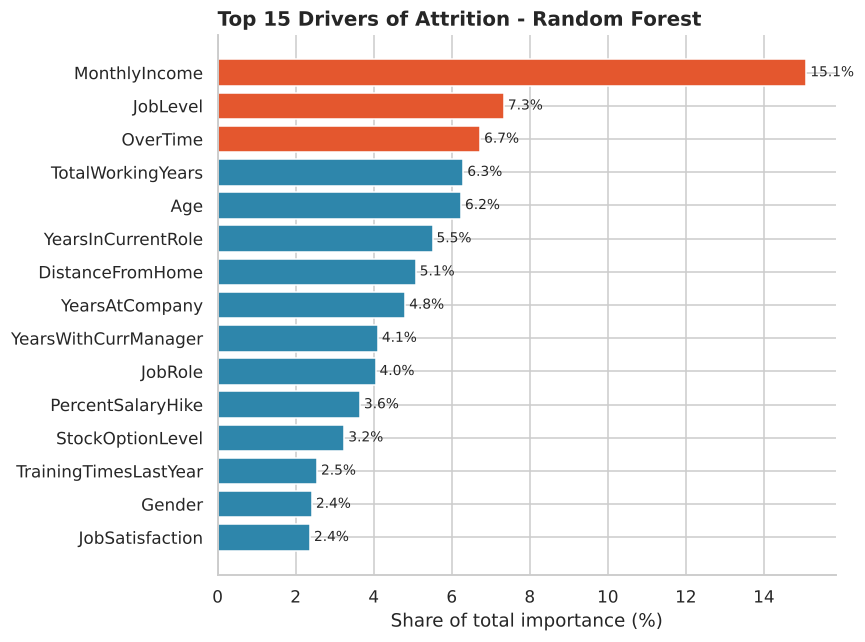

In [11]:
mt.plot_feature_importance(fitted["Random Forest"], "Random Forest", IMG);

In [12]:
mt.feature_importance(fitted["Random Forest"], 10)

MonthlyIncome           15.09
JobLevel                 7.34
OverTime                 6.73
TotalWorkingYears        6.30
Age                      6.24
YearsInCurrentRole       5.51
DistanceFromHome         5.08
YearsAtCompany           4.81
YearsWithCurrManager     4.11
JobRole                  4.05
dtype: float64

Pay and seniority (`MonthlyIncome`, `JobLevel`, `TotalWorkingYears`, `Age`) dominate, followed by **overtime**,
commute distance and manager tenure - consistent with the EDA findings.

## 6. Generate predictions for every employee
Each employee is scored with **out-of-fold** probabilities (5-fold): the model scoring an employee never saw that employee during training, so the dashboard figures are not inflated by memorisation.

In [13]:
proba = mt.out_of_fold_predictions(best, X, y, thr)
preds = mt.export_predictions(df, proba, thr, "../data/processed/attrition_predictions.csv")
preds[["EmployeeID", "Department", "JobRole", "Attrition", "Attrition_Probability",
       "Predicted_Attrition", "Risk_Level", "Prediction_Outcome"]].head(10)

,EmployeeID,Department,JobRole,Attrition,Attrition_Probability,Predicted_Attrition,Risk_Level,Prediction_Outcome
0,1942,Research & Development,Manufacturing Director,No,0.1303,No,Low,True Negative
1,1298,Research & Development,Research Scientist,No,0.3780,No,Medium,True Negative
2,1272,Human Resources,HR Manager,No,0.1492,No,Low,True Negative
3,1775,Research & Development,Manufacturing Director,No,0.2431,No,Low,True Negative
4,1421,Sales,Sales Manager,No,0.1775,No,Low,True Negative
5,2091,Sales,Sales Executive,No,0.2461,No,Low,True Negative
6,1428,Research & Development,Laboratory Technician,No,0.1118,No,Low,True Negative
7,2394,Sales,Sales Executive,No,0.2875,No,Low,True Negative
8,1232,Research & Development,Laboratory Technician,No,0.3769,No,Medium,True Negative
9,2056,Sales,Sales Executive,No,0.1263,No,Low,True Negative


In [14]:
print(preds["Risk_Level"].value_counts().to_string())
print()
print(preds["Prediction_Outcome"].value_counts().to_string())

Risk_Level
Low       791
Medium    538
High      141

Prediction_Outcome
True Negative     1080
False Positive     163
False Negative     119
True Positive      108


In [15]:
# Actual attrition rate by predicted risk tier - a quick calibration check
(preds.groupby("Risk_Level")["Attrition_Flag"].agg(Employees="size", Actual_Attrition_Rate="mean")
      .reindex(["Low", "Medium", "High"]).round(3))

,Employees,Actual_Attrition_Rate
Risk_Level,,
Low,791,0.058
Medium,538,0.217
High,141,0.454


The risk tiers separate well: the *High* tier has several times the real attrition rate of the *Low* tier - the property HR actually needs to prioritise retention conversations.

In [16]:
import joblib
joblib.dump({"model": best, "threshold": thr, "features": list(X.columns), "name": best_name},
            "../models/attrition_model.joblib")
print("Model saved -> models/attrition_model.joblib")

Model saved -> models/attrition_model.joblib


## 7. Scoring a new employee (demo)

In [17]:
bundle = joblib.load("../models/attrition_model.joblib")
new_emp = X.iloc[[0]].copy()
new_emp.loc[:, "OverTime"] = "Yes"; new_emp.loc[:, "MonthlyIncome"] = 3200; new_emp.loc[:, "Age"] = 24
p = bundle["model"].predict_proba(new_emp)[0, 1]
print(f"Attrition probability: {p:.1%}  ->  {'LEAVE' if p >= bundle['threshold'] else 'STAY'} (threshold {bundle['threshold']:.2f})")

Attrition probability: 50.2%  ->  LEAVE (threshold 0.50)
